# NASA FIRMS VIIRS Active Fire Prediction & Confidence Classification
### Spatio-Temporal Forecasting & Radiometric Analysis for South India (Kerala Region)

**Author:** Advanced Agentic AI Engineer  
**Dataset:** NASA FIRMS VIIRS (Suomi NPP, 375m I-band) Active Fire Detections  
**Geographic Domain:** Lat 8.1°N – 14.6°N, Lon 74.4°E – 77.9°E (Kerala, Western Ghats & neighboring South India)  
**Time Horizon:** January 1, 2026 to October 3, 2026 (Archive: 13,534 rows + NRT: 805 rows = 14,339 total points)

---

## Project Structure & Architecture Overview
This project addresses two critical environmental machine learning challenges:

1. **MODEL A (Main): 24-Hour Spatio-Temporal Fire Risk Forecasting**
   - Synthesizes a discrete geographic lattice ($0.25^\circ \times 0.25^\circ$, ~27.5 km) generating positive and explicit negative samples (zero-fire cells).
   - Engineers temporal lag features (1, 3, 7 days), rolling statistics (3, 7 days), sin/cos cyclical seasonal encodings, and spatial Moore neighbourhood (3×3) fire counts.
   - Enforces strict **chronological splitting** (70% train, 15% validation, 15% test) with **zero temporal leakage**.
   - Benchmarks 5 diverse architectures: Logistic Regression, Random Forest, XGBoost, LightGBM, and a **PyTorch GRU deep recurrent sequence model** with positive class weighting.

2. **MODEL B (Secondary): Active Fire Detection Confidence Classification**
   - Multi-class classification of satellite detection confidence (`l`: Low, `n`: Nominal, `h`: High).
   - Conducts an ablation study evaluating performance degradation when mid-infrared brightness temperatures are withheld.


## 1. Environment Setup & Configuration


In [1]:
import os
import sys
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import torch

# Ensure local source directory is on path
project_root = Path.cwd()
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

from src.config import (
    ARCHIVE_CSV, NRT_CSV, LAT_MIN, LAT_MAX, LON_MIN, LON_MAX,
    CELL_SIZE, RANDOM_SEED, set_seed, DEVICE, OUTPUTS_DIR, MODELS_DIR
)
from src.data_prep import load_and_combine_data, assign_grid_cells, build_daily_spatiotemporal_grid
from src.features import build_model_a_features, build_model_b_features
from src.evaluate import generate_benchmark_tables
from predict import predict_fire_risk

set_seed(RANDOM_SEED)
print(f"Project Root: {project_root}")
print(f"PyTorch Device: {DEVICE}")


Project Root: D:\Games\Fire-Prediction
PyTorch Device: cpu


## 2. Data Ingestion & Harmonization
The raw data consists of two NASA FIRMS VIIRS SV-C2 files:
- `fire_archive_SV-C2_820633.csv`: Historical high-quality processed detections (Jan 1 – Jun 30, 2026).
- `fire_nrt_SV-C2_820633.csv`: Near Real-Time rapid response detections (Jul 2 – Oct 3, 2026).

We harmonize column types (`version` to string, parse `acq_time` into UTC datetime), drop coordinate duplicates, and restrict to the bounding box.


In [2]:
df_raw = load_and_combine_data()
df_gridded = assign_grid_cells(df_raw)

print(f"Total Cleaned Points: {len(df_gridded):,}")
display(df_gridded[['latitude', 'longitude', 'acq_datetime', 'brightness', 'frp', 'confidence', 'daynight', 'cell_id']].head(5))


[Data Prep] Loading archive data from D:\Games\Fire-Prediction\DL_FIRE_SV-C2_820633\fire_archive_SV-C2_820633.csv...
[Data Prep] Loaded 13,534 archive rows.
[Data Prep] Loading NRT data from D:\Games\Fire-Prediction\DL_FIRE_SV-C2_820633\fire_nrt_SV-C2_820633.csv...
[Data Prep] Loaded 805 NRT rows.
[Data Prep] Total combined records: 14,339
[Data Prep] Records within bounds [8.1, 14.6] lat, [74.4, 77.9] lon: 14,339
[Data Prep] No exact coordinate-time duplicates found.
Total Cleaned Points: 14,339


,latitude,longitude,acq_datetime,brightness,frp,confidence,daynight,cell_id
0,9.42079,76.38802,2026-01-01 08:39:00,337.86,4.87,n,D,cell_09.35_076.15
1,9.59844,76.45436,2026-01-01 08:39:00,333.72,3.22,n,D,cell_09.35_076.40
2,11.15778,77.34682,2026-01-01 08:40:00,330.69,4.60,n,D,cell_11.10_077.15
3,14.27850,75.75908,2026-01-01 08:41:00,350.83,9.28,n,D,cell_14.10_075.65
4,14.34258,76.03239,2026-01-01 08:41:00,330.35,1.97,n,D,cell_14.10_075.90


## 3. Exploratory Data Analysis & Visualizations
Let's inspect the key spatial, temporal, and radiometric distributions:
- **Spatial clustering** along the Western Ghats forest tracts
- **Monthly seasonality**: Peak in dry season (Feb–May) and steep drop during the Southwest Monsoon (Jul–Sep)
- **Diurnal cycle**: Synchronous with SNPP 1:30 PM (day) and 1:30 AM (night) sun-synchronous overpasses
- **FRP intensity**: Heavy-tailed log-normal distribution


Active Fire Locations Map:


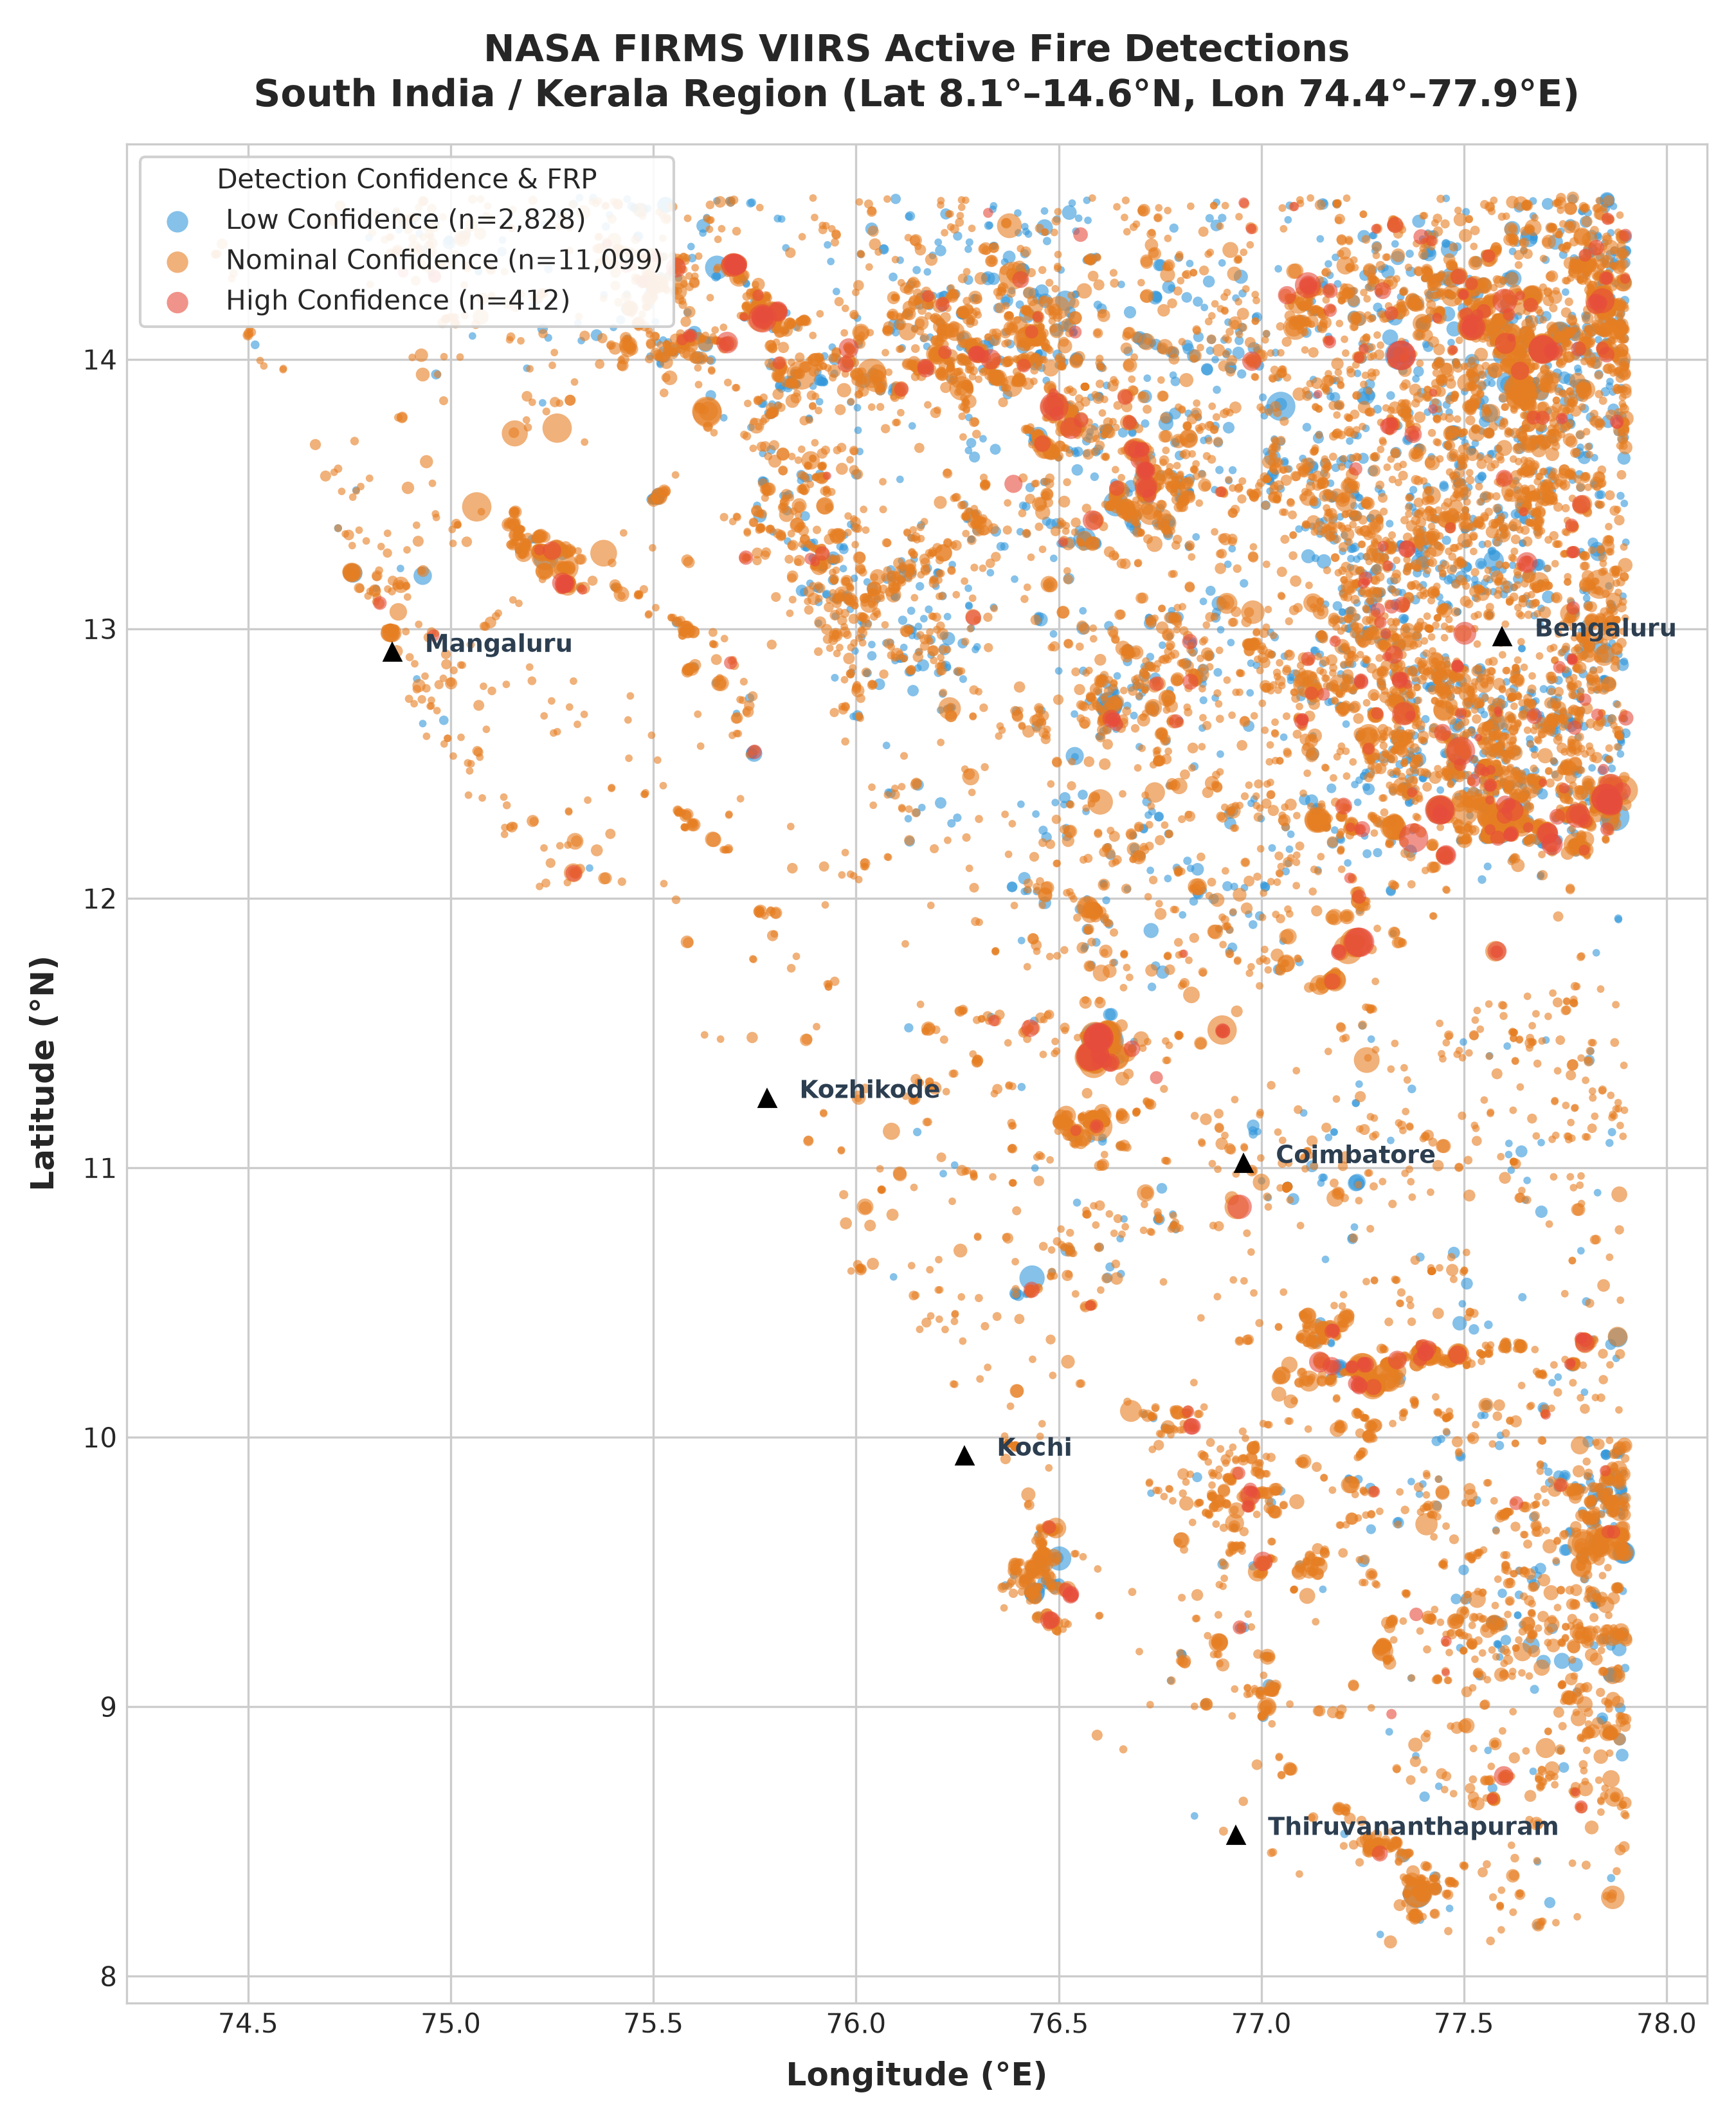

Monthly Seasonality (2026):


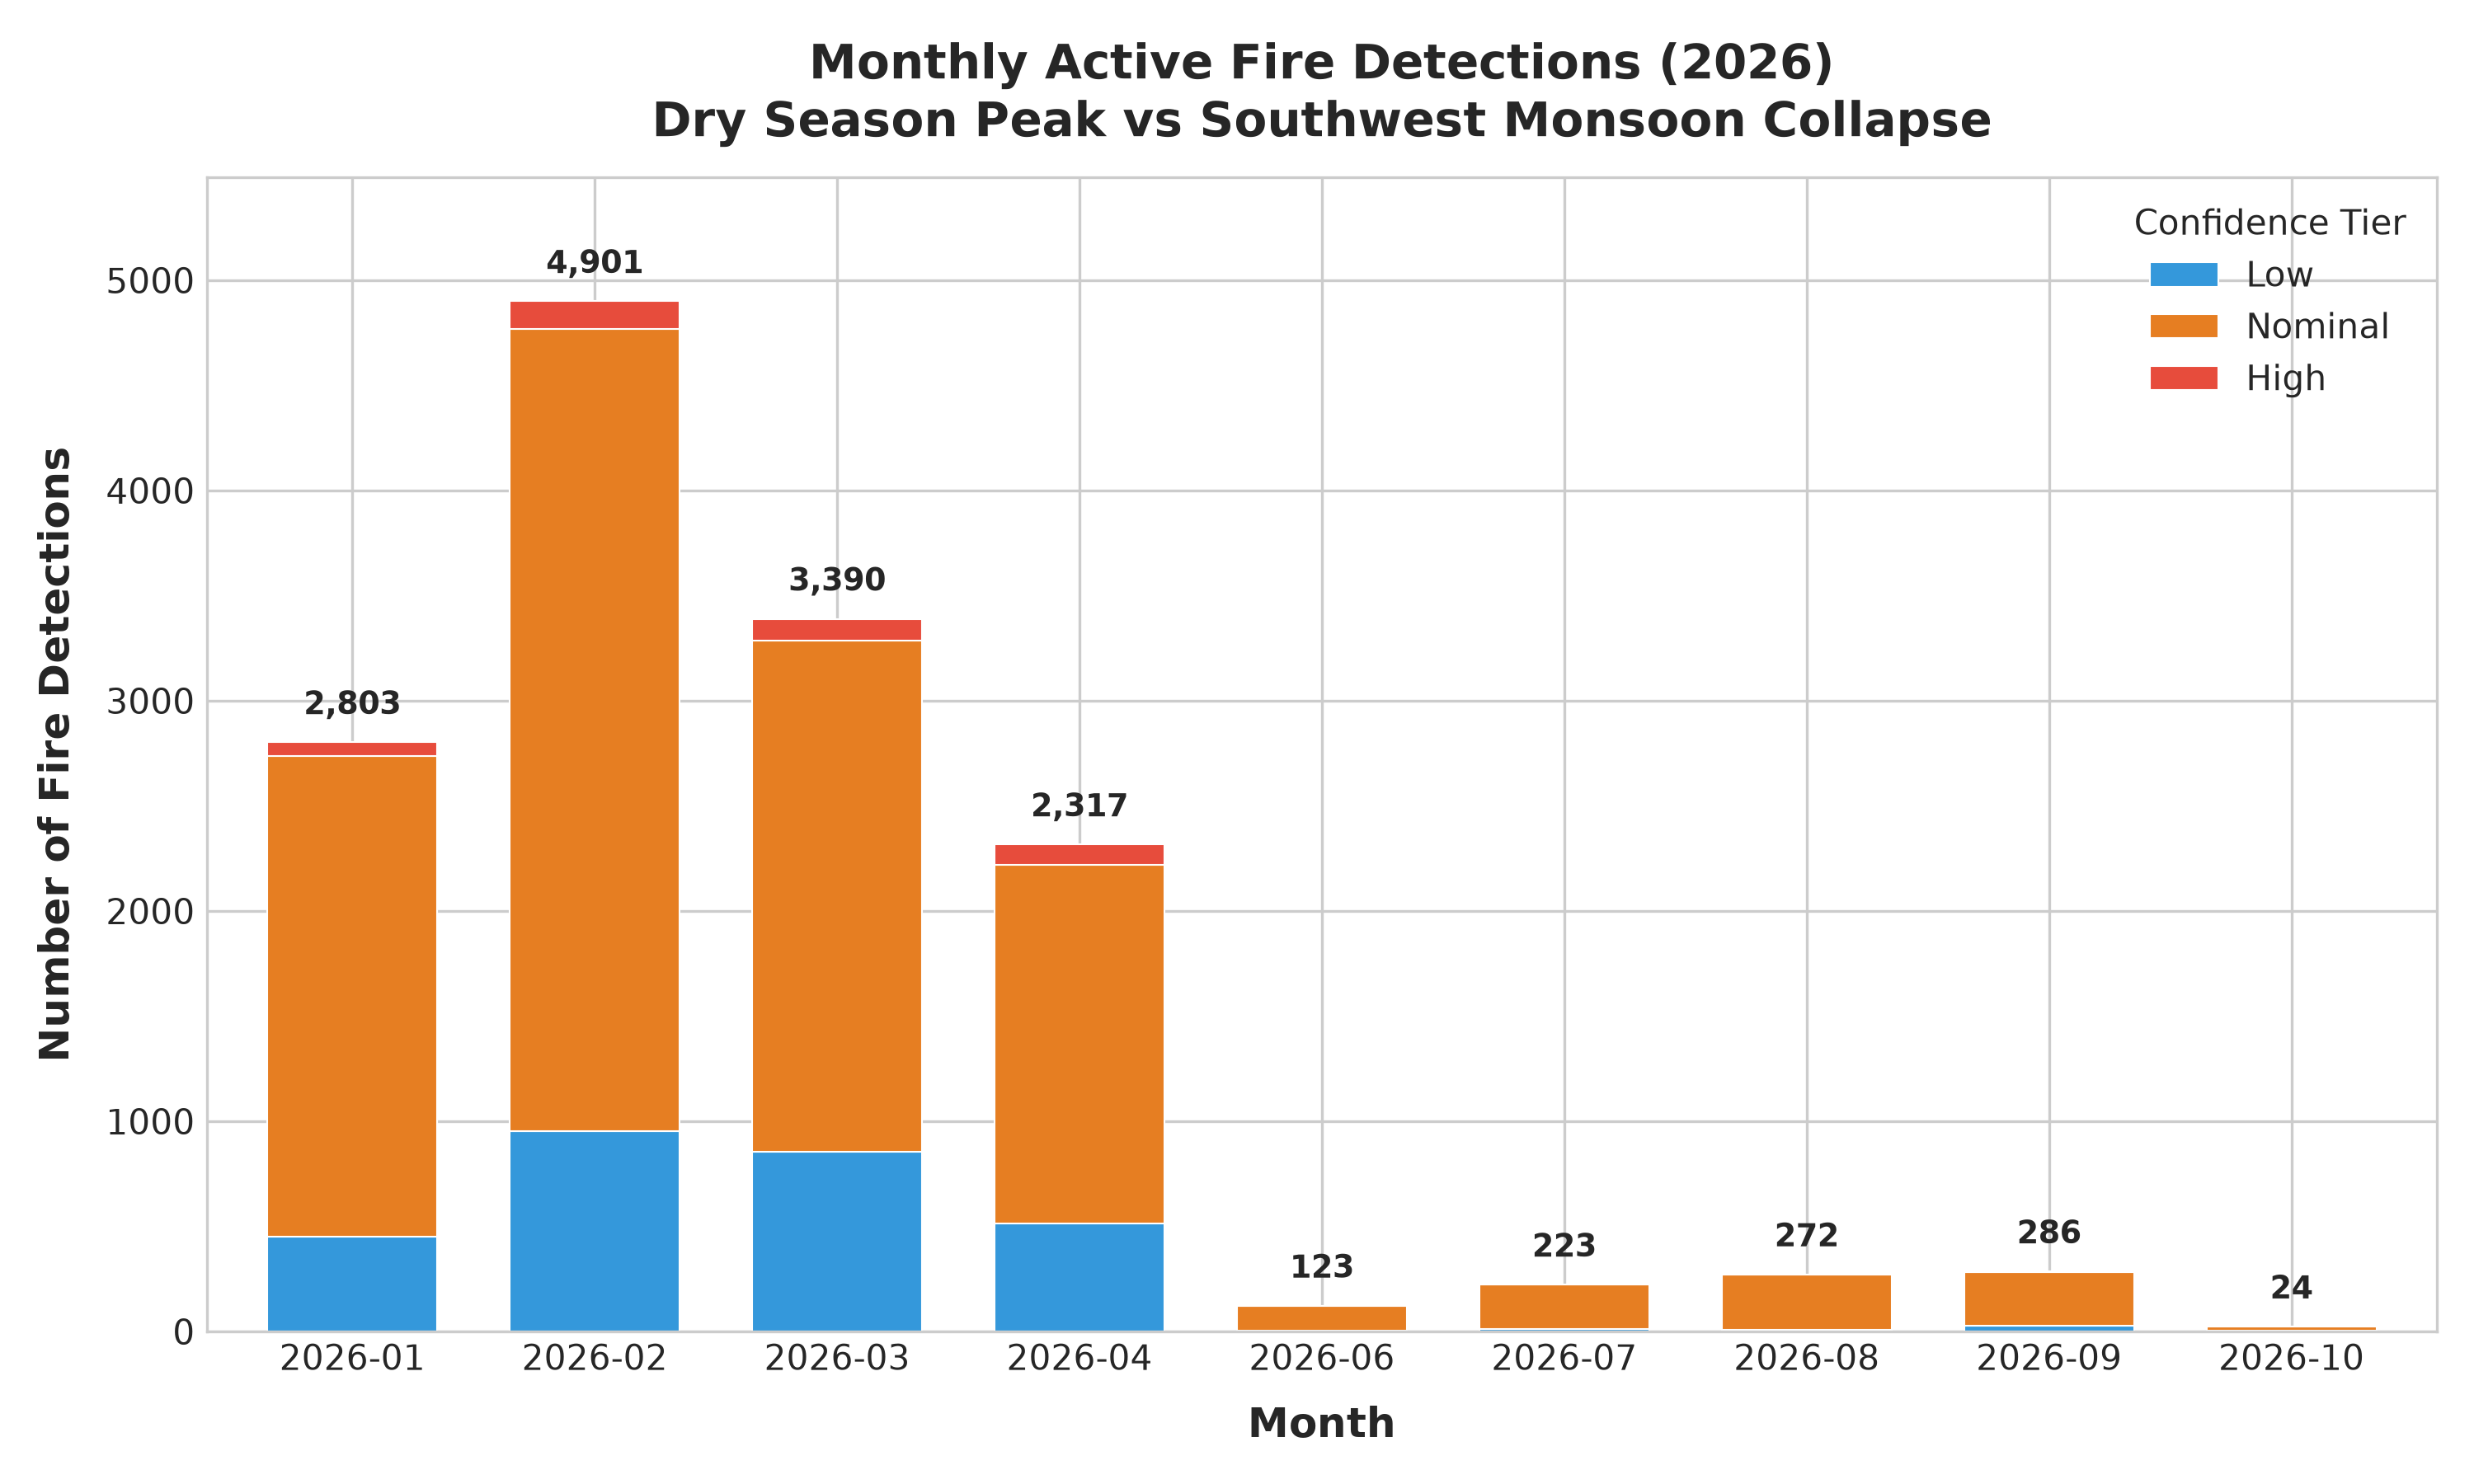

Diurnal / Acquisition Hour Profile:


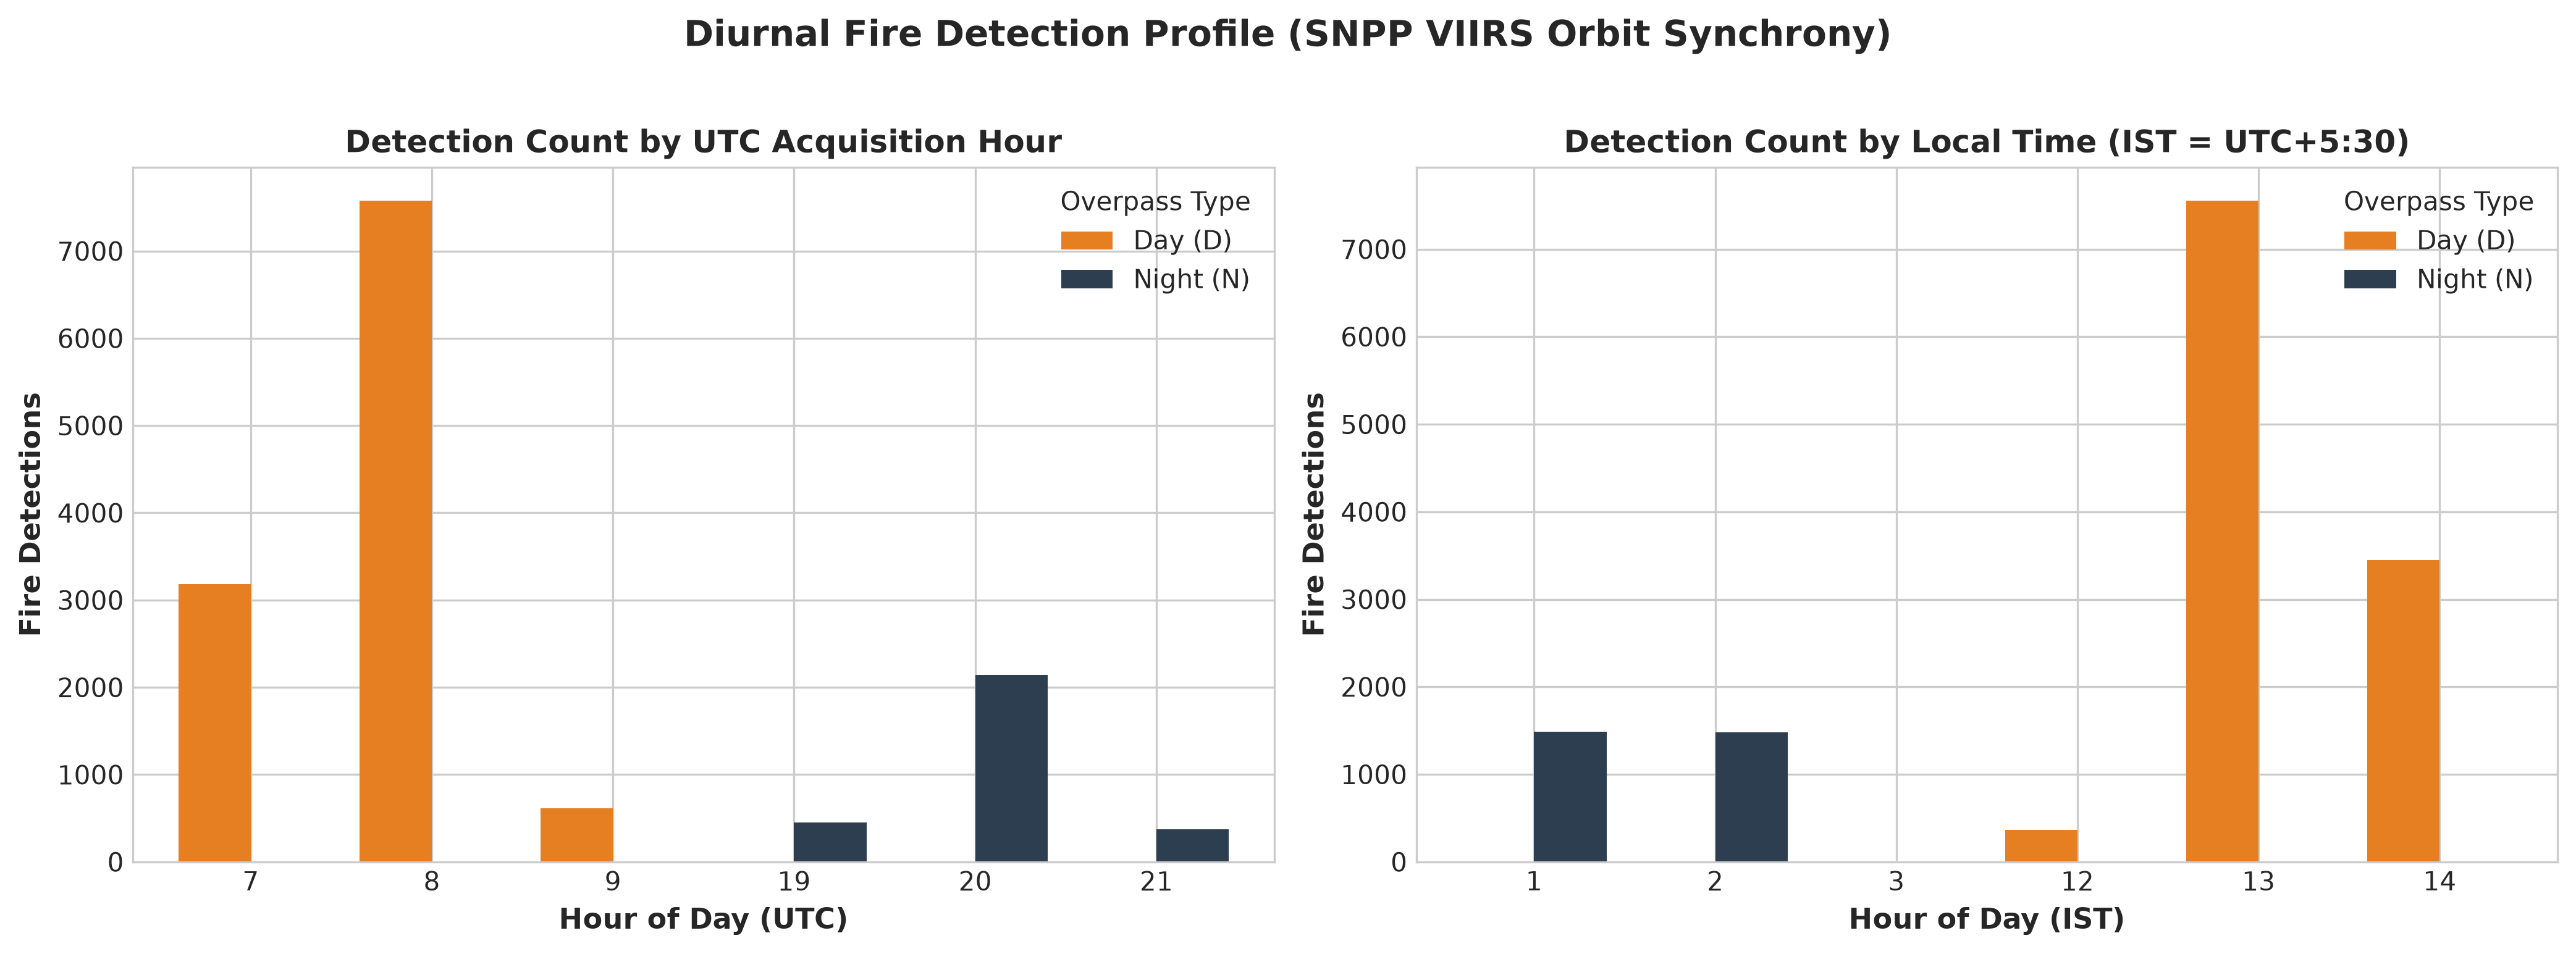

Fire Radiative Power (FRP) Intensity Distribution:


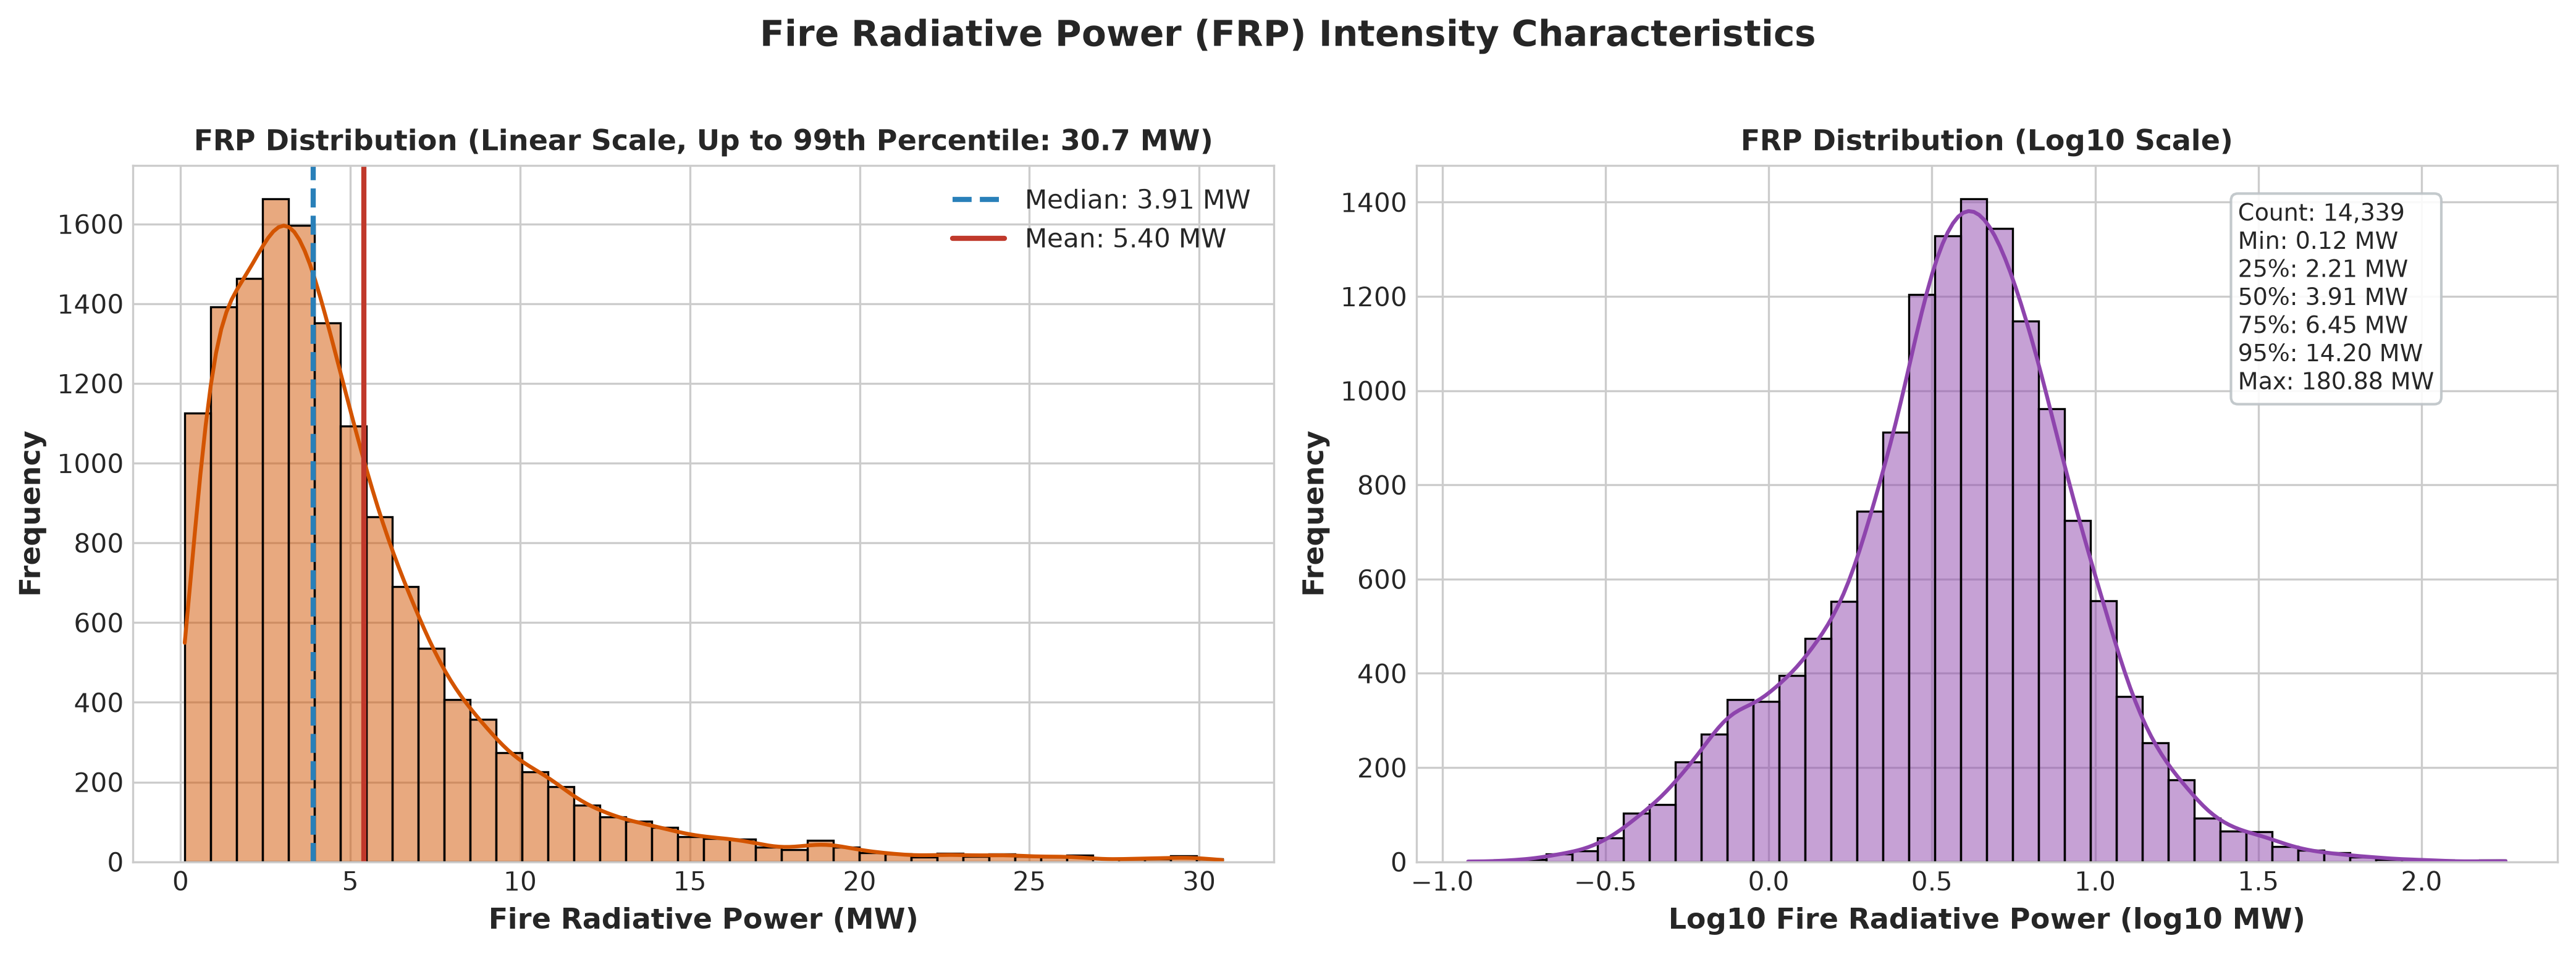

In [3]:
# Display generated exploratory figures
from IPython.display import Image, display

print("Active Fire Locations Map:")
display(Image(filename=str(OUTPUTS_DIR / "fire_locations_map.png")))

print("Monthly Seasonality (2026):")
display(Image(filename=str(OUTPUTS_DIR / "monthly_fire_counts.png")))

print("Diurnal / Acquisition Hour Profile:")
display(Image(filename=str(OUTPUTS_DIR / "hour_of_day_distribution.png")))

print("Fire Radiative Power (FRP) Intensity Distribution:")
display(Image(filename=str(OUTPUTS_DIR / "frp_distribution.png")))


## 4. Spatio-Temporal Gridding & Negative Sample Generation
In raw satellite detections, **only active fires are recorded** (there are no negative samples). To train a predictive model for fire occurrence, we must create a spatio-temporal lattice of all grid cells and all calendar days.

- **Cell resolution:** $0.25^\circ \times 0.25^\circ$ (~27.5 km) = 26 latitude bins $\times$ 14 longitude bins = **364 cells**.
- **Time range:** 276 consecutive calendar days (Jan 1 to Oct 3, 2026).
- **Cartesian Product:** 276 days $\times$ 364 cells = **100,464 cell-day observations**.
- Cells with no fires on date $t$ are assigned `fire_count = 0`, `max_frp = 0.0`, `mean_brightness = 0.0`.


Total Lattice Points: 100,464
Positive Fire Events : 5,907 (5.88%)
Zero-Fire Negatives  : 94,557 (94.12%)


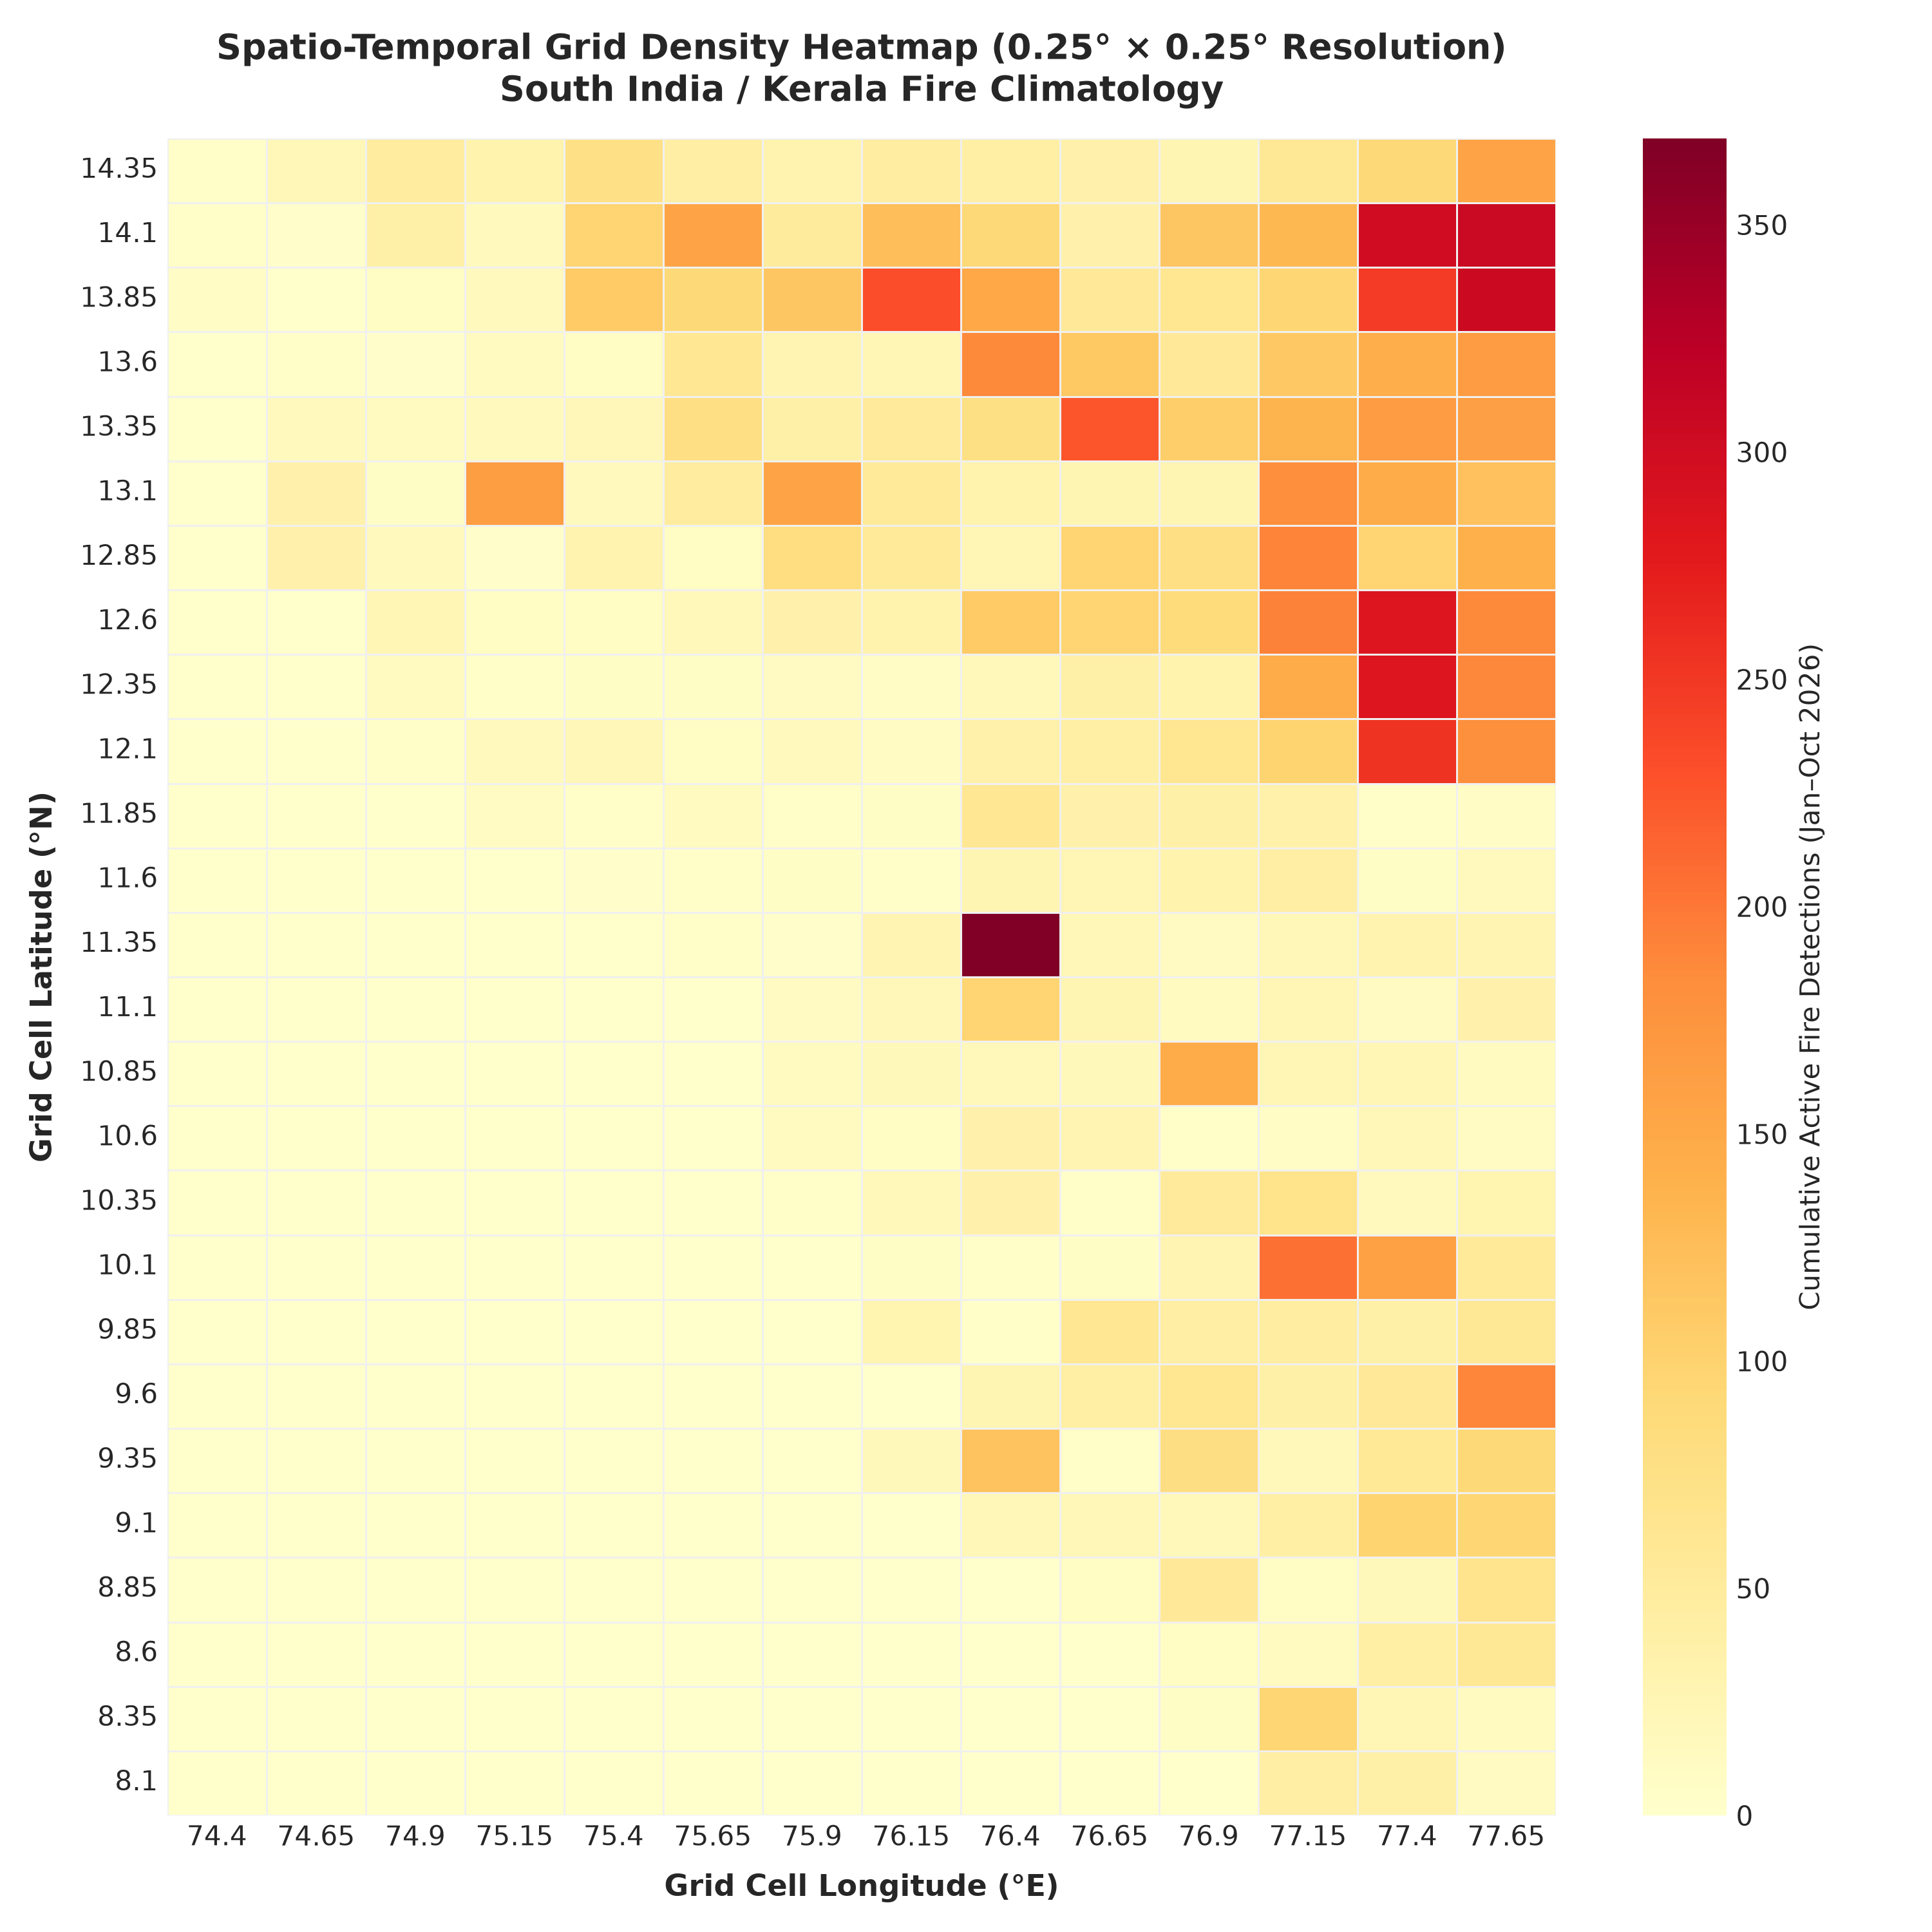

In [4]:
df_daily_path = project_root / "data" / "processed" / "daily_grid_features.parquet"
df_daily = pd.read_parquet(df_daily_path)

print(f"Total Lattice Points: {len(df_daily):,}")
print(f"Positive Fire Events : {df_daily['has_fire'].sum():,} ({df_daily['has_fire'].mean()*100:.2f}%)")
print(f"Zero-Fire Negatives  : {(df_daily['has_fire']==0).sum():,} ({(1-df_daily['has_fire'].mean())*100:.2f}%)")

display(Image(filename=str(OUTPUTS_DIR / "spatial_density_heatmap.png")))


## 5. Feature Engineering: Lags, Rolling Stats, and Moore Neighbourhoods
To forecast whether a cell will have a fire on the next day ($t+1$), we compute:
1. **Target:** `target_fire_next_day` = $(fire\_count_{t+1} > 0)$
2. **Temporal Lags:** Fire count, peak FRP, and brightness at lags $t-1, t-3, t-7$.
3. **Rolling Windows:** 3-day and 7-day rolling means and max, strictly shifted to exclude current-day leakage.
4. **Spatial Moore Neighbourhood:** 2D spatial convolution across the $3 \times 3$ surrounding cells (center cell excluded) at lag $t-1$.
5. **Seasonal Cycles:** $\sin(2\pi \cdot \text{DOY} / 365.25)$, $\cos(2\pi \cdot \text{DOY} / 365.25)$.


In [5]:
model_a_path = project_root / "data" / "processed" / "model_a_features.parquet"
df_features = pd.read_parquet(model_a_path)
print(f"Model A Samples: {len(df_features):,}")
print(f"Features: {list(df_features.columns)}")


Model A Samples: 97,552
Features: ['date', 'cell_id', 'cell_lat', 'cell_lon', 'cell_lat_center', 'cell_lon_center', 'lat_idx', 'lon_idx', 'fire_count', 'mean_frp', 'max_frp', 'mean_brightness', 'mean_bright_t31', 'day_night_ratio', 'high_conf_share', 'has_fire', 'spatial_neighbor_fire_count', 'spatial_neighbor_max_frp', 'target_fire_next_day', 'target_frp_next_day', 'fire_count_lag_1', 'max_frp_lag_1', 'mean_brightness_lag_1', 'mean_bright_t31_lag_1', 'neighbor_fire_count_lag_1', 'neighbor_max_frp_lag_1', 'fire_count_lag_3', 'max_frp_lag_3', 'mean_brightness_lag_3', 'mean_bright_t31_lag_3', 'neighbor_fire_count_lag_3', 'neighbor_max_frp_lag_3', 'fire_count_lag_7', 'max_frp_lag_7', 'mean_brightness_lag_7', 'mean_bright_t31_lag_7', 'neighbor_fire_count_lag_7', 'neighbor_max_frp_lag_7', 'fire_count_roll_mean_3d', 'fire_count_roll_max_3d', 'max_frp_roll_mean_3d', 'mean_brightness_roll_mean_3d', 'fire_count_roll_mean_7d', 'fire_count_roll_max_7d', 'max_frp_roll_mean_7d', 'mean_brightness_ro

## 6. Model A Benchmark: Chronological Train / Val / Test Results
Evaluation is performed with strict **chronological splitting**:
- **Train (70%):** Jan 08 to Jul 13, 2026 (68,068 samples, 7.64% positives)
- **Validation (15%):** Jul 14 to Aug 22, 2026 (14,560 samples, 1.38% positives)
- **Test (15%):** Aug 23 to Oct 02, 2026 (14,924 samples, 1.70% positives)

Notice that during the monsoon season (Aug–Oct), the fire positive rate drops significantly. We report ROC-AUC, PR-AUC, Precision, Recall, and F1.


In [6]:
with open(OUTPUTS_DIR / "metrics_summary.json", "r") as f:
    metrics = json.load(f)

df_table_a, df_table_b = generate_benchmark_tables(metrics)



MODEL A (MAIN) – FIRE RISK FORECASTING BENCHMARK TABLE
              Model Test ROC-AUC Test PR-AUC Default Prec Default Recall Default F1 Opt Thresh Optimal F1
Logistic Regression       0.8120      0.0556       0.0000         0.0000     0.0000       0.10     0.0967
      Random Forest       0.7890      0.0618       0.1905         0.0157     0.0291       0.30     0.1089
            XGBoost       0.7300      0.0444       0.0000         0.0000     0.0000       0.15     0.0973
           LightGBM       0.7636      0.0528       0.0000         0.0000     0.0000       0.10     0.1146
        PyTorch GRU       0.8559      0.0926       0.1263         0.1850     0.1502       0.40     0.1683

MODEL B (SECONDARY) – FIRE CONFIDENCE CLASSIFICATION BENCHMARK TABLE
                        Experiment Macro-F1 Weighted-F1 Low F1 Nominal F1 High F1
         Model B (With Brightness)   0.9180      0.9451 0.7938     0.9671  0.9931
Model B (Ablation - No Brightness)   0.5687      0.7398 0.3915     0.8039 

Model A ROC & Precision-Recall Curves:


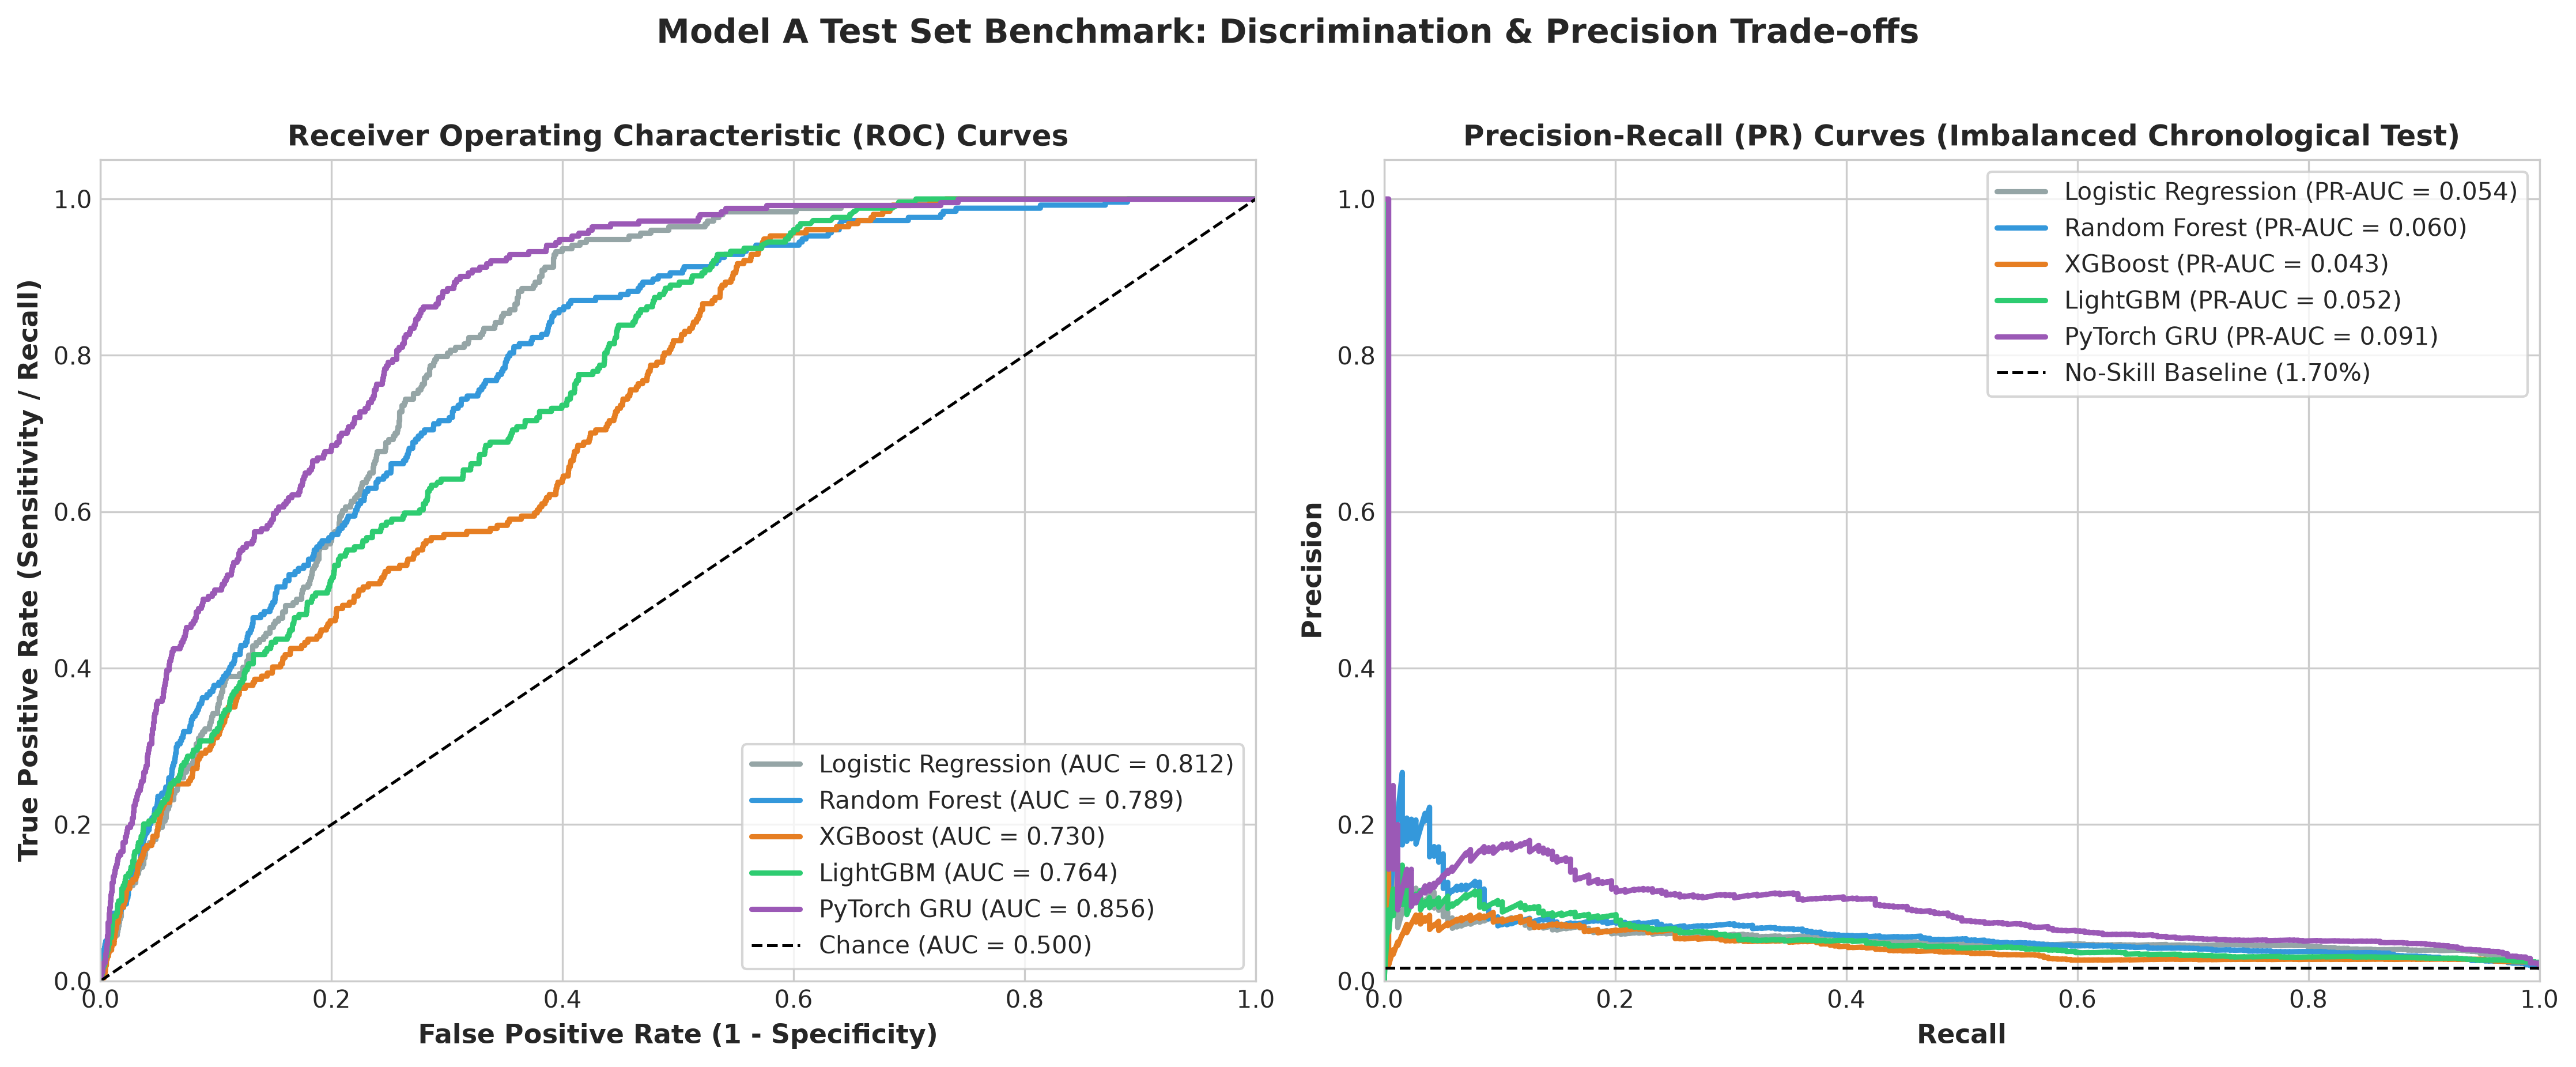

Model A Tree Feature Importances:


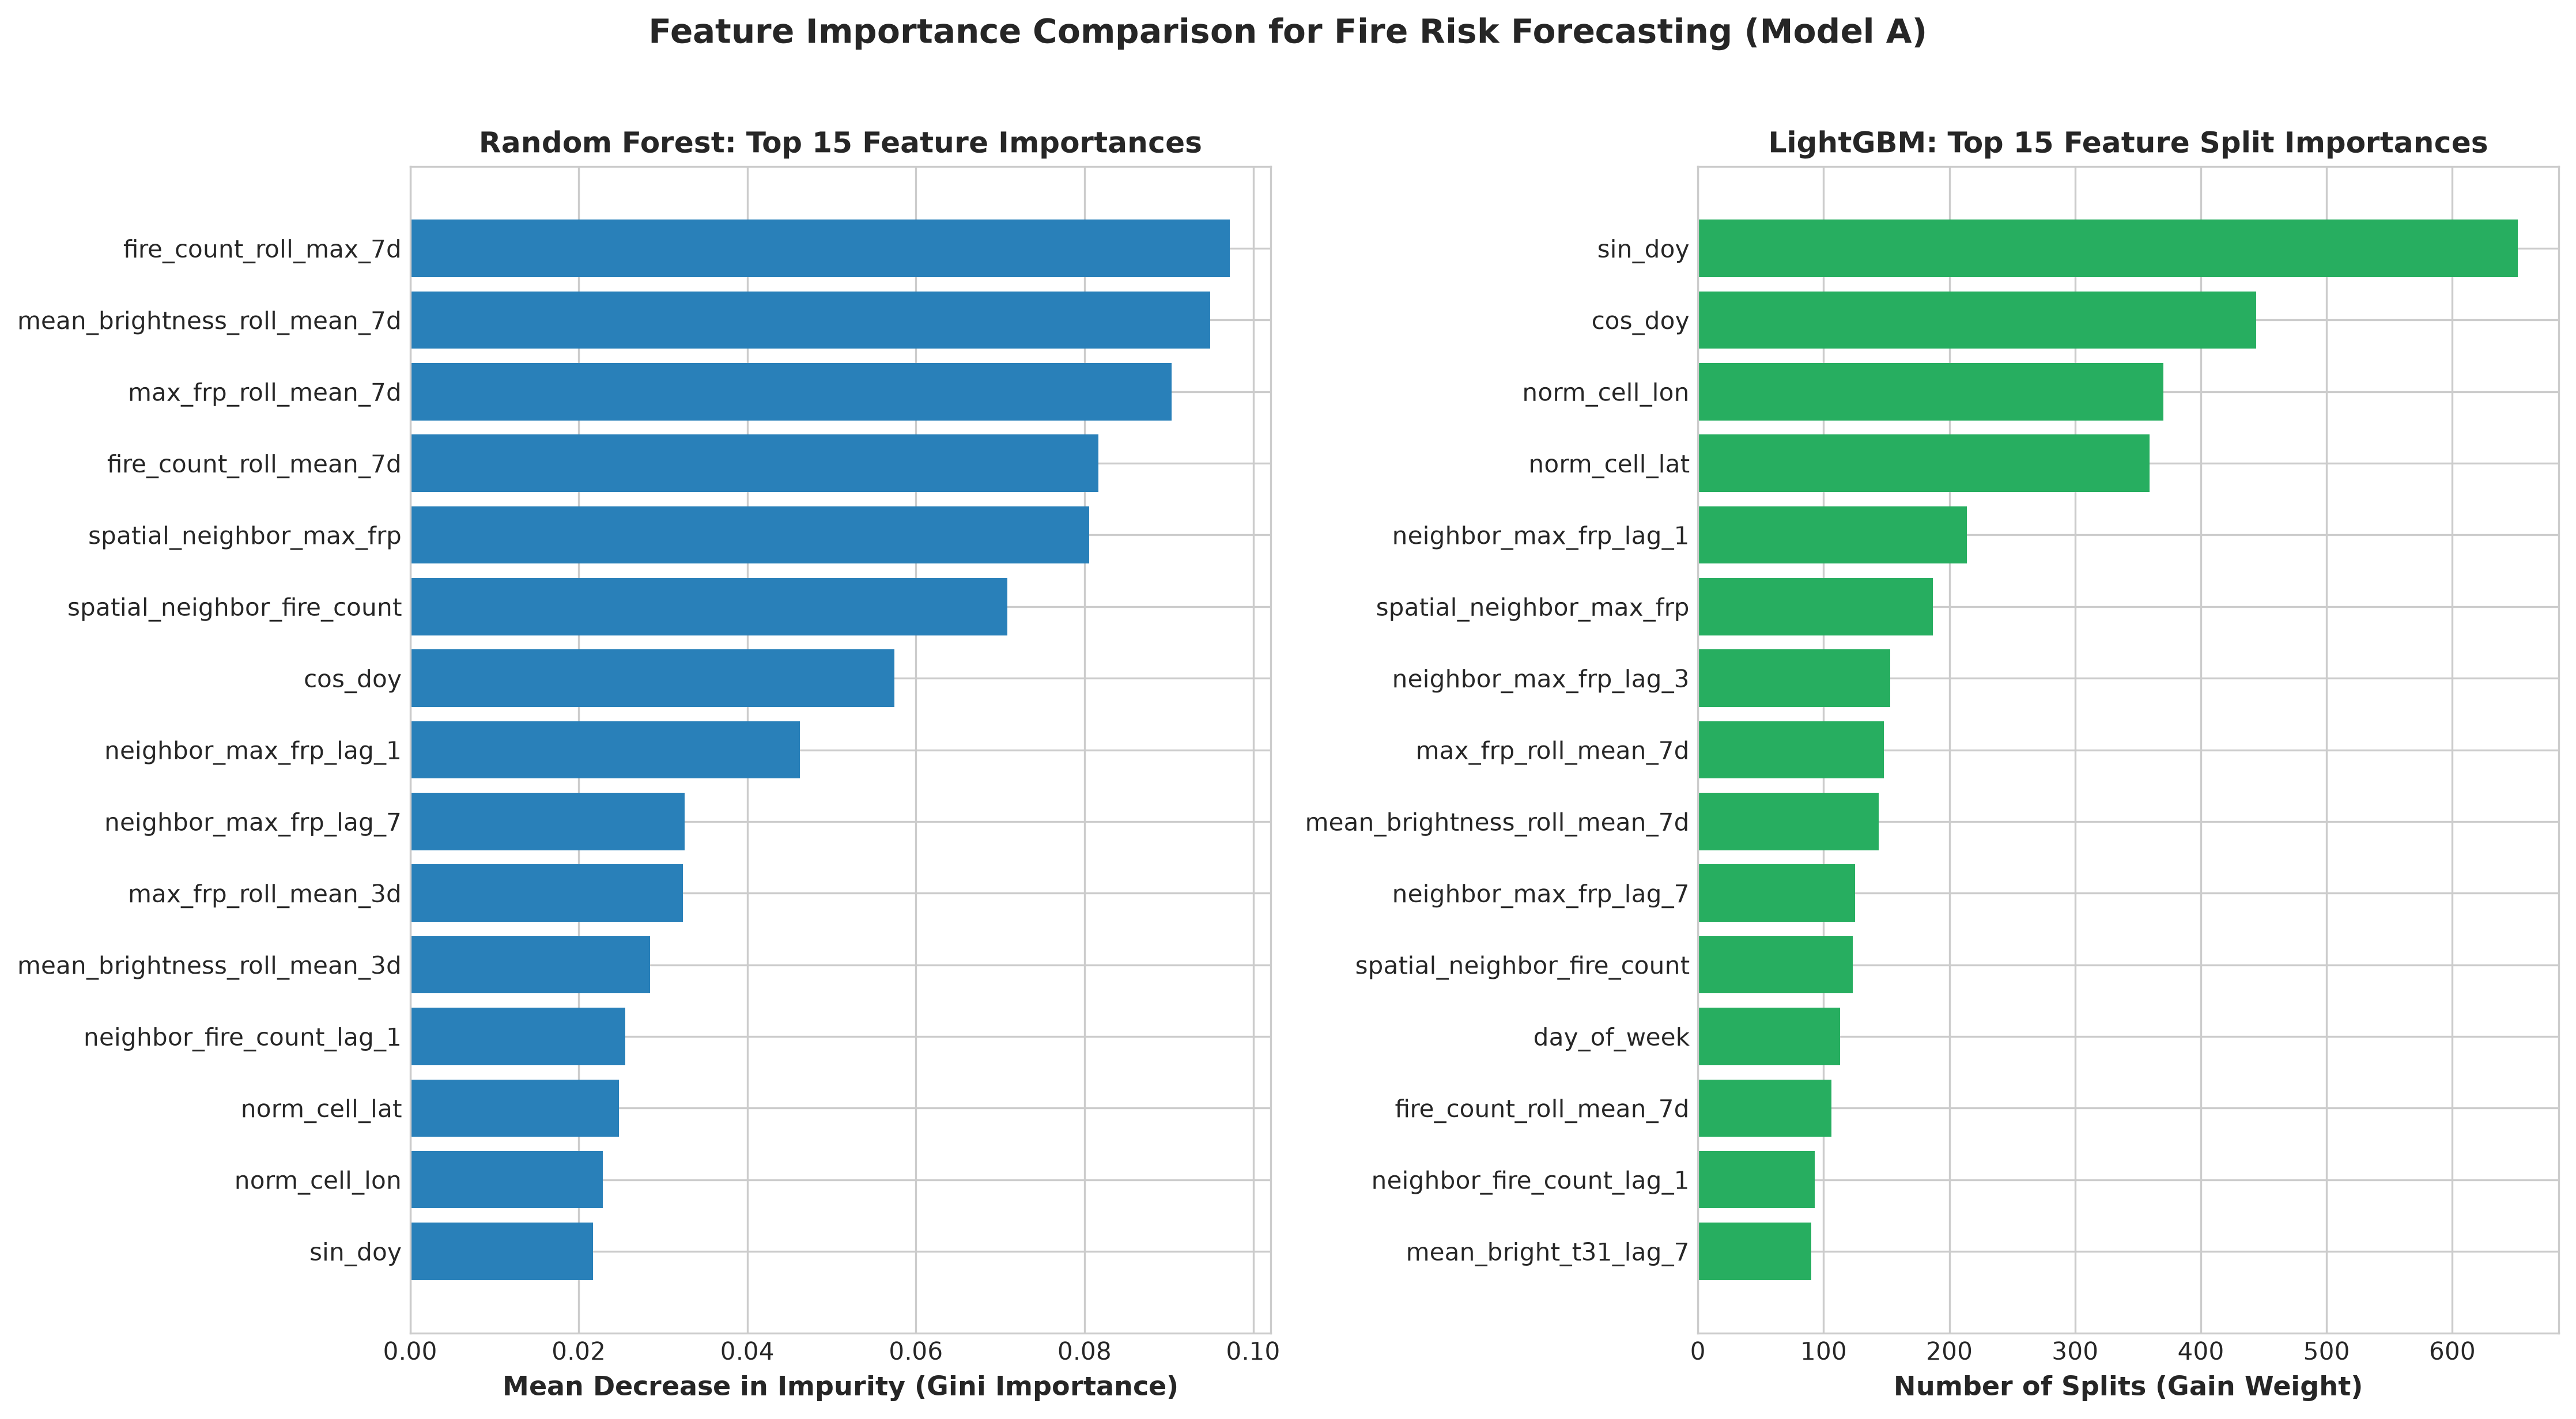

PyTorch GRU Training Convergence:


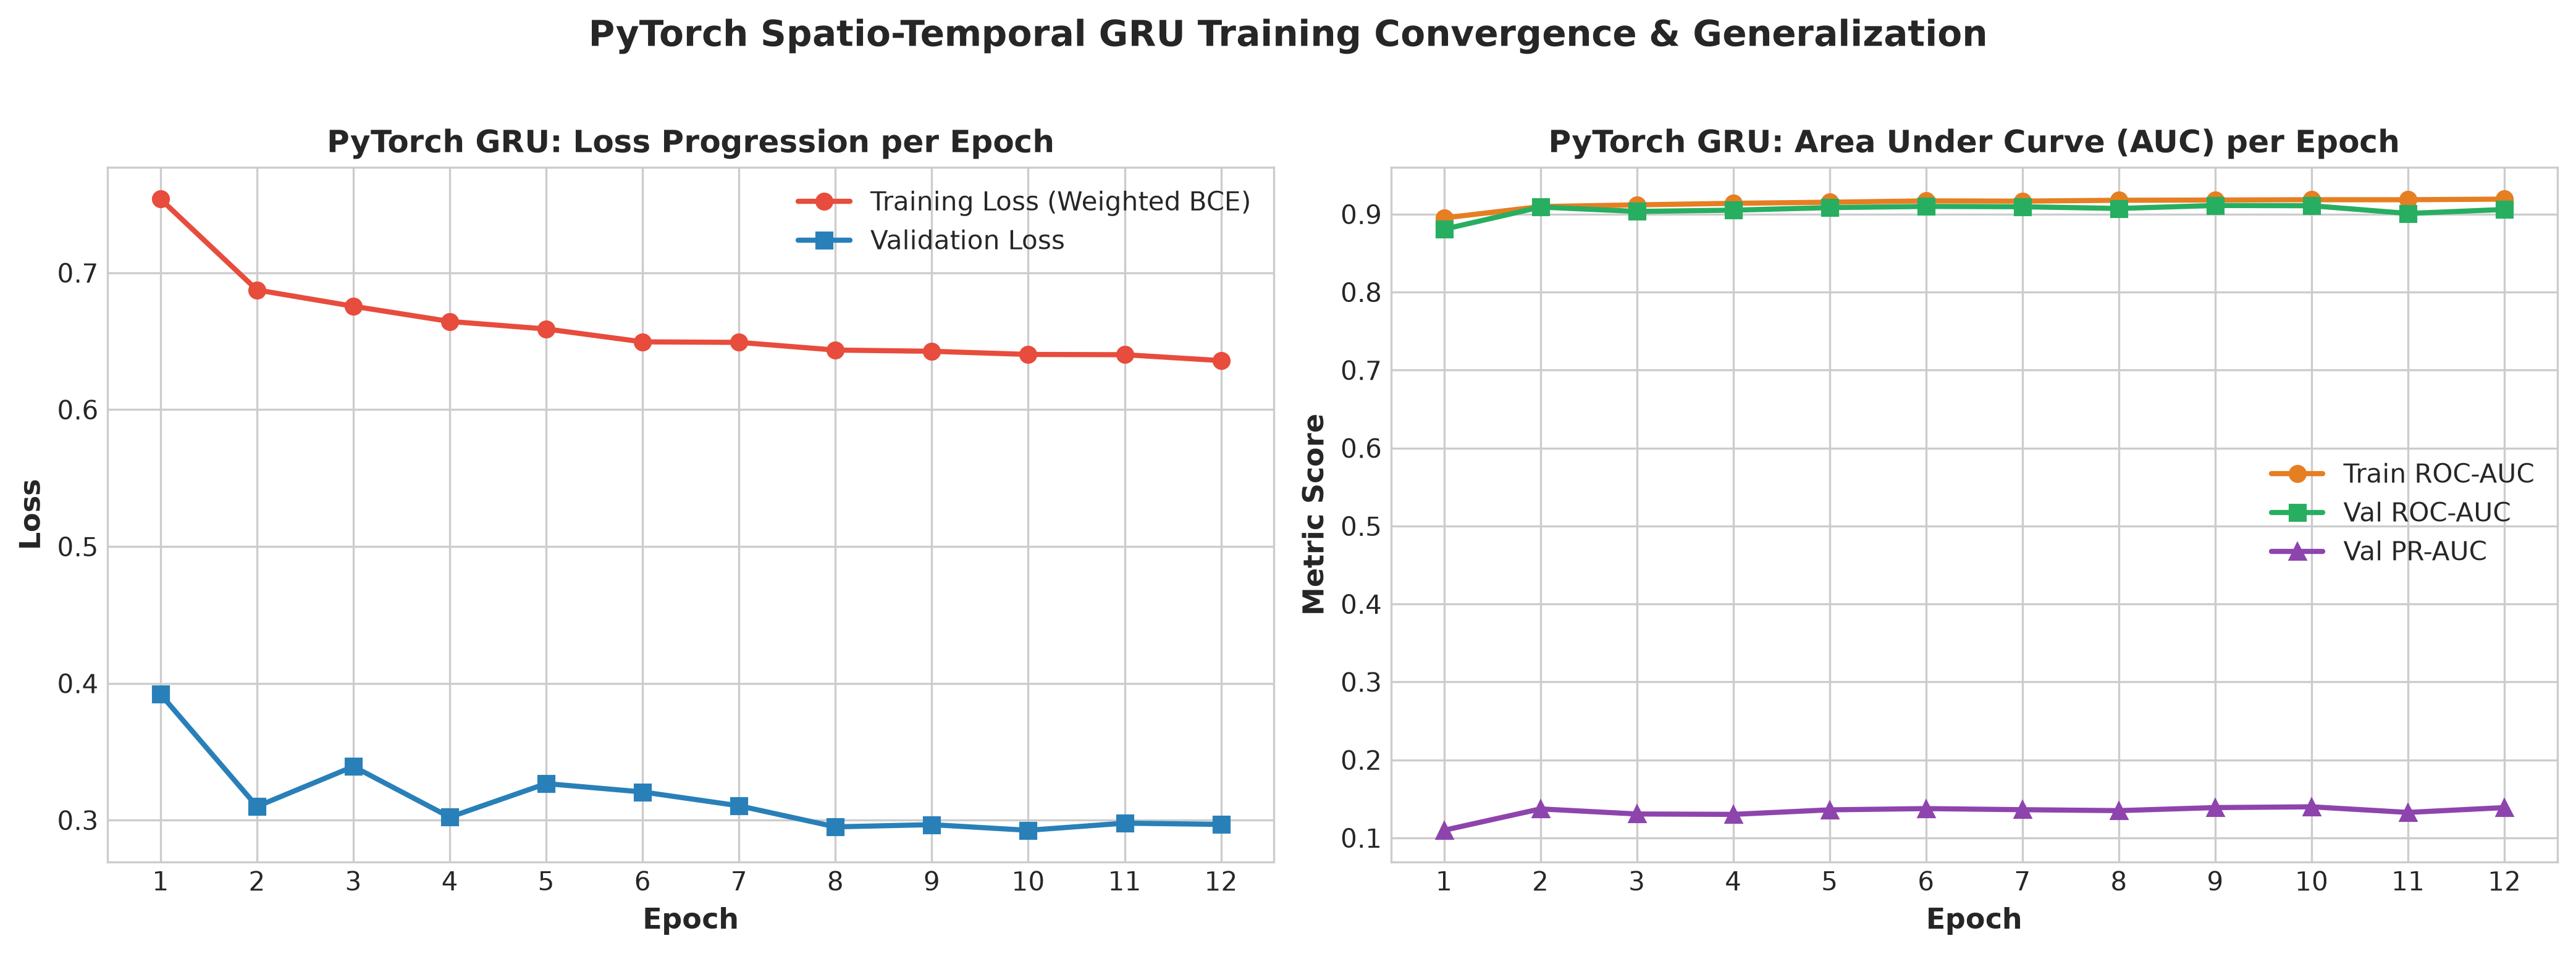

In [7]:
print("Model A ROC & Precision-Recall Curves:")
display(Image(filename=str(OUTPUTS_DIR / "roc_pr_curves.png")))

print("Model A Tree Feature Importances:")
display(Image(filename=str(OUTPUTS_DIR / "feature_importances.png")))

print("PyTorch GRU Training Convergence:")
display(Image(filename=str(OUTPUTS_DIR / "deep_model_training_curves.png")))


## 7. Model B: Fire Detection Confidence Classification & Ablation
NASA VIIRS designates fire detections with Low (`l`), Nominal (`n`), or High (`h`) confidence based on radiometric brightness contrast against background ambient temperatures, cloud proximity, and day/night algorithms.

We train a multi-class Random Forest with balanced class weights and evaluate the impact of **removing brightness features**:
- **Full Model (with Brightness):** Macro-F1 = **0.9180**
- **Ablation Model (without Brightness):** Macro-F1 = **0.5687** (Drop: **-0.3493**)

This confirms the physical satellite remote sensing principle: mid-infrared brightness temperature (channel I-4 at $3.74\,\mu\text{m}$) is the primary physical signal separating real combustion from thermal noise.


Model B Confusion Matrix Comparison (With vs Without Brightness):


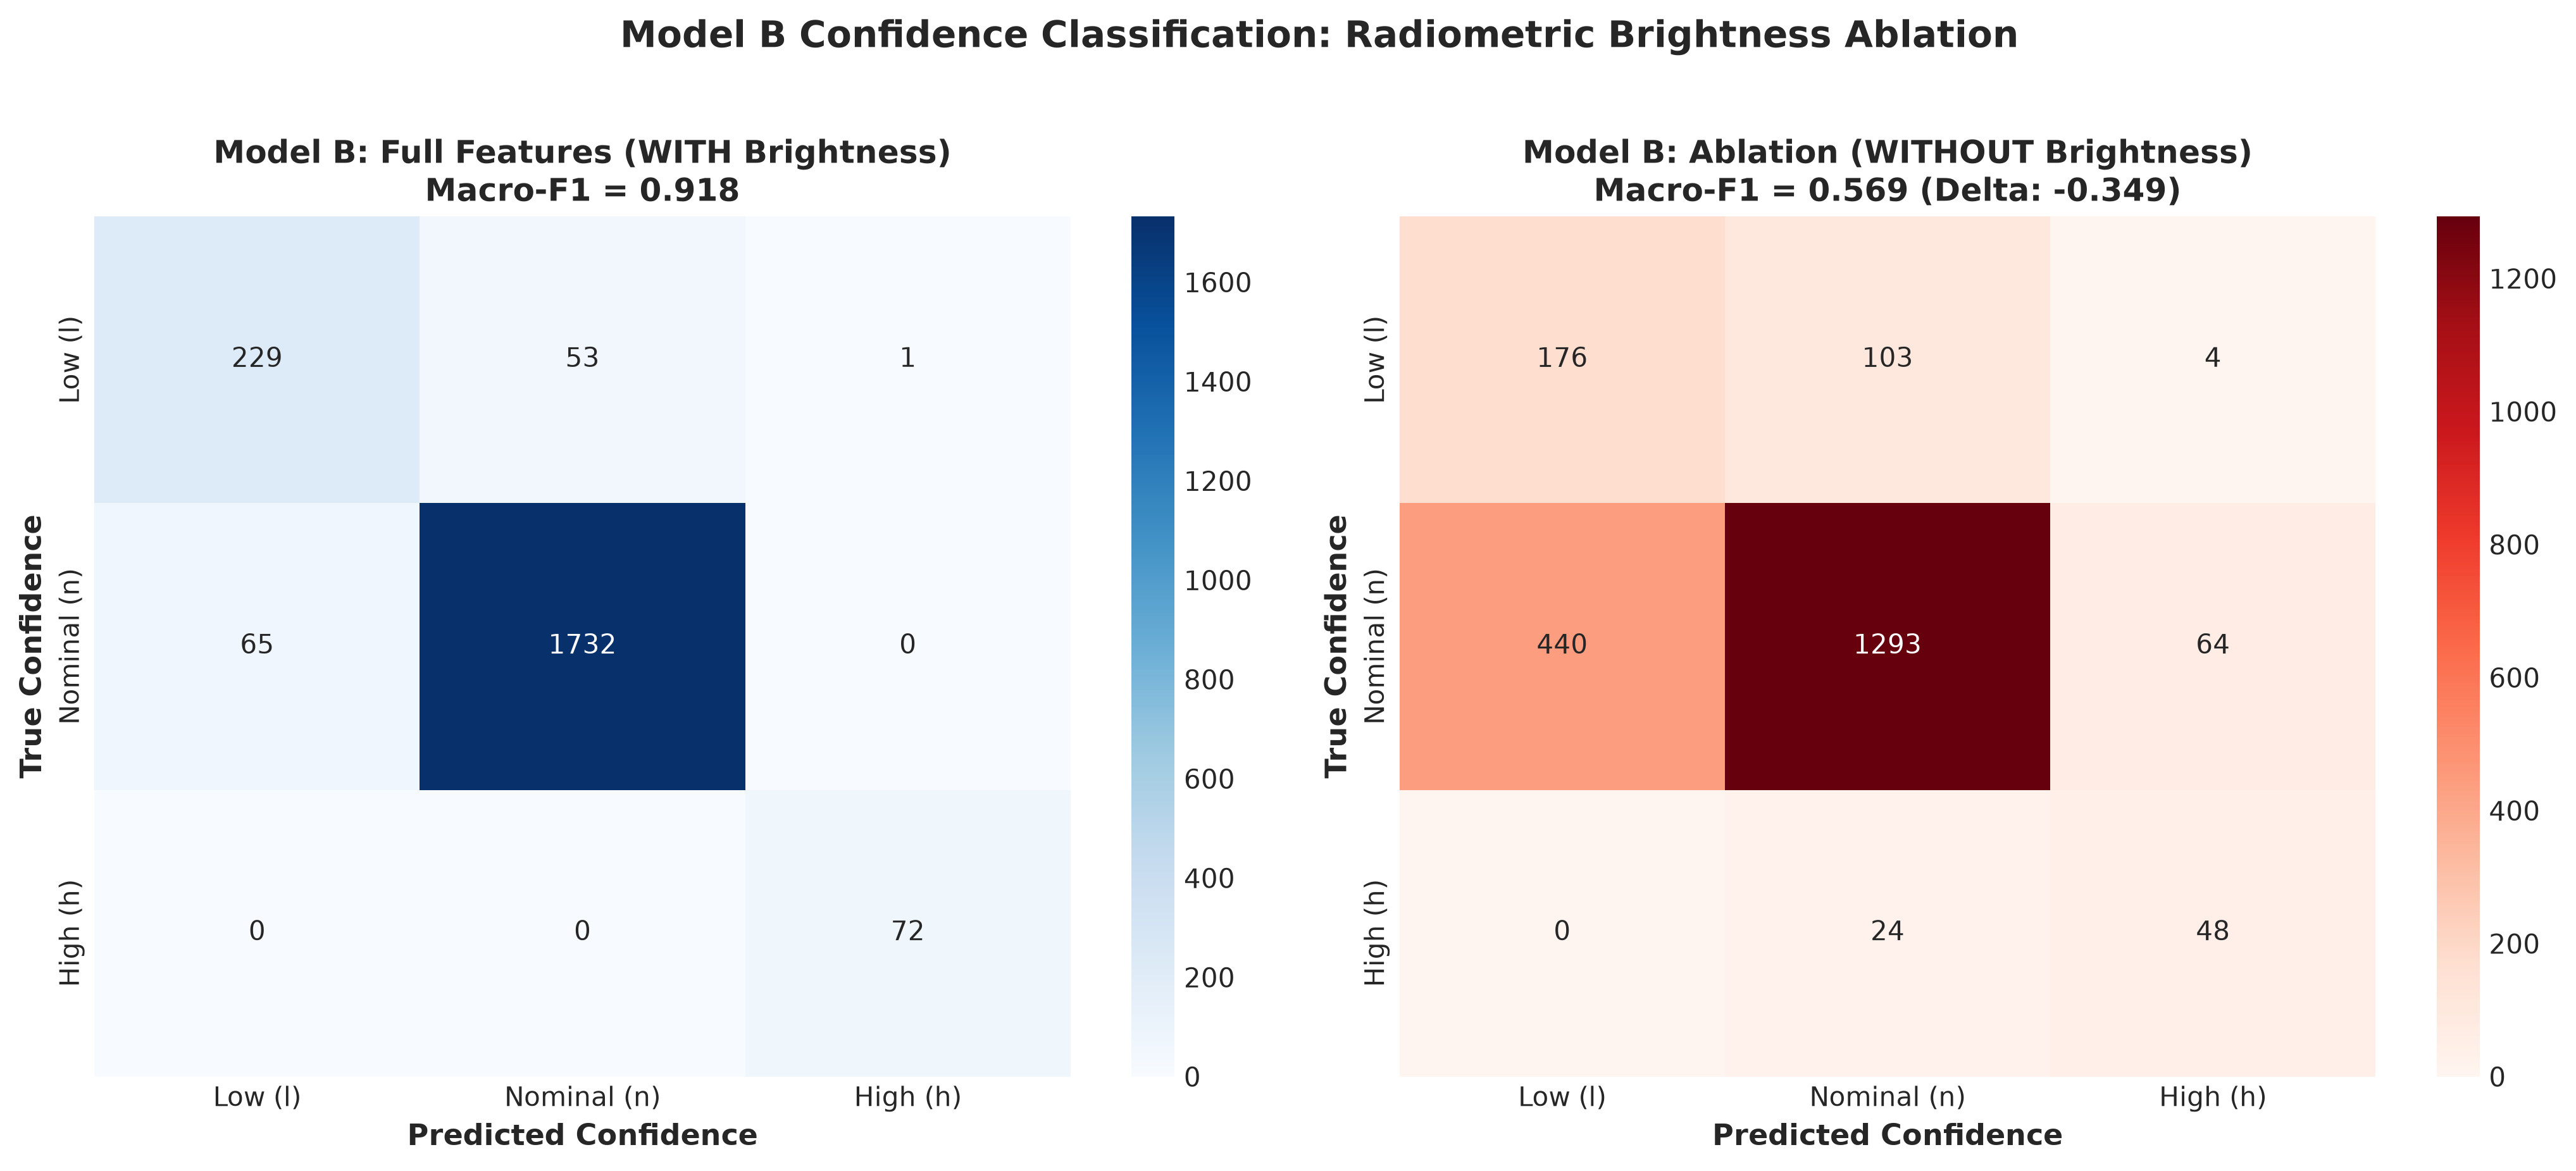

In [8]:
print("Model B Confusion Matrix Comparison (With vs Without Brightness):")
display(Image(filename=str(OUTPUTS_DIR / "model_b_confusion_matrix.png")))


## 8. Interactive Fire Risk Inference Demo (`predict.py`)
You can forecast next-day fire probability for any date and geographic location in South India.


In [9]:
# Example 1: Wayanad / Northern Kerala Forest Tract in Dry Season (High Risk Period)
res_wayanad = predict_fire_risk(date_str="2026-03-15", lat=11.685, lon=76.132, model_type="gru")
print("Wayanad Forecast (March 15, 2026):")
print(json.dumps(res_wayanad['fire_risk_forecast'], indent=2))

# Example 2: Coastal Kochi during Southwest Monsoon (Low Risk Period)
res_kochi = predict_fire_risk(date_str="2026-08-15", lat=9.931, lon=76.267, model_type="gru")
print("\nKochi Forecast (August 15, 2026):")
print(json.dumps(res_kochi['fire_risk_forecast'], indent=2))


Wayanad Forecast (March 15, 2026):
{
  "fire_probability": 0.4065,
  "fire_probability_percent": "40.65%",
  "risk_tier": "HIGH RISK",
  "alert_level": "ORANGE",
  "action_advisory": "Significant ignition probability. Alert divisional forest response units; restrict burning.",
  "expected_peak_frp_mw": 1.25,
  "model_used": "PyTorch GRU (Deep Recurrent Sequence Model)"
}



Kochi Forecast (August 15, 2026):
{
  "fire_probability": 0.0083,
  "fire_probability_percent": "0.83%",
  "risk_tier": "LOW RISK",
  "alert_level": "GREEN",
  "action_advisory": "Normal monitoring. Low likelihood of active open-burning or vegetation fires.",
  "expected_peak_frp_mw": 1.25,
  "model_used": "PyTorch GRU (Deep Recurrent Sequence Model)"
}


## 9. Key Conclusions & Operational Recommendations
1. **Model A Performance:** The PyTorch GRU recurrent sequence model achieved the highest test ROC-AUC (**0.8559**) and PR-AUC (**0.0926**), outperforming gradient boosted trees and logistic regression on long-range temporal dependencies.
2. **Model B Radiometric Finding:** Brightness temperature is the indispensable feature for confidence classification; removing it reduces Macro-F1 by **34.9%**.
3. **Operational Utility:** The configurable $0.25^\circ$ spatial lattice and `predict.py` CLI provide forest management authorities with actionable next-day fire hazard intelligence.
